# BottleneckIQ — ML Simulation Lab
This notebook performs model training using the simulation dataset `ed_full_schema_1k.csv`.

Steps:
1. Clinical feature engineering (IQ logic)
2. Throughput / bottleneck labeling
3. Random Forest pipeline evaluation
4. Save model + MultiLabelBinarizer

In [22]:
# 1. Imports
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import MultiLabelBinarizer
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sns.set(style='whitegrid')

DATA_DIR = Path('.')
SIM_FILE = DATA_DIR / 'ed_full_schema_1k.csv'
print('simulation file:', SIM_FILE)

simulation file: ed_full_schema_1k.csv


In [23]:
# 2. Load data
df = pd.read_csv(SIM_FILE)
print('rows', len(df))
print(df.columns.tolist())
print(df.head(3))

rows 5424
['stay_id', 'subject_id', 'hadm_id', 'timestamps', 'activity', 'gender', 'race', 'arrival_transport', 'disposition', 'seq_num', 'icd_code', 'icd_version', 'icd_title', 'temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp', 'pain', 'acuity', 'chiefcomplaint', 'rhythm', 'name', 'gsn', 'ndc', 'etc_rn', 'etccode', 'etcdescription', 'med_rn', 'gsn_rn']
    stay_id  subject_id   hadm_id           timestamps activity gender  \
0  40000000    20000000  30000000  2026-03-20 19:00:00    entry      F   
1  40000000    20000000  30000000  2026-03-20 19:22:00   triage      F   
2  40000000    20000000  30000000  2026-03-20 19:41:00    vital      F   

      race arrival_transport disposition  seq_num  ... chiefcomplaint  rhythm  \
0  UNKNOWN           WALK-IN         NaN      NaN  ...        DYSPNEA     NaN   
1  UNKNOWN           WALK-IN         NaN      NaN  ...        DYSPNEA     NaN   
2  UNKNOWN           WALK-IN         NaN      NaN  ...        DYSPNEA   Sinus   

  name  gs

In [24]:
# 3. Clinical feature engineering (IQ logic)
if 'chiefcomplaint' in df.columns:
    complaint_lists = (
        df['chiefcomplaint'].fillna('').astype(str)
          .str.split(',')
          .apply(lambda tokens: [t.strip().lower() for t in tokens if t.strip()])
    )
    mlb = MultiLabelBinarizer()
    complaint_matrix = pd.DataFrame(mlb.fit_transform(complaint_lists), columns=mlb.classes_, index=df.index)
    # limit to top 20
    top20 = complaint_matrix.sum().sort_values(ascending=False).head(20).index.tolist()
    complaint_features = complaint_matrix[top20].add_prefix('complaint_')
    df = pd.concat([df, complaint_features], axis=1)
    print('Top 20 complaint features:', top20)
else:
    mlb = None
    print('chiefcomplaint not found–skipping complaint features')

# Time-based features
timestamp_col = 'timestamp' if 'timestamp' in df.columns else 'timestamps' if 'timestamps' in df.columns else None
if not timestamp_col:
    raise ValueError('timestamp column required for temporal cycles')

df[timestamp_col] = pd.to_datetime(df[timestamp_col], errors='coerce')
if timestamp_col != 'timestamp':
    df['timestamp'] = df[timestamp_col]

df['hour_of_day'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

# Intensity indicator
if 'Acuity' in df.columns and 'Arrival' in df.columns:
    df['high_intensity'] = ((df['Acuity'] <= 2) & (df['Arrival'].astype(str).str.lower() == 'ambulance')).astype(int)
else:
    df['high_intensity'] = 0

# One-hot arrival mode if exists
if 'Arrival' in df.columns:
    df = pd.concat([df, pd.get_dummies(df['Arrival'].astype(str), prefix='Arrival', dummy_na=False)], axis=1)

print('feature columns example:', df.columns.tolist()[:40])

Top 20 complaint features: ['dyspnea', 'change in mental status', 'fever', 'fall', 'chest pain', 'abd pain', 's/p assault']
feature columns example: ['stay_id', 'subject_id', 'hadm_id', 'timestamps', 'activity', 'gender', 'race', 'arrival_transport', 'disposition', 'seq_num', 'icd_code', 'icd_version', 'icd_title', 'temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp', 'pain', 'acuity', 'chiefcomplaint', 'rhythm', 'name', 'gsn', 'ndc', 'etc_rn', 'etccode', 'etcdescription', 'med_rn', 'gsn_rn', 'complaint_dyspnea', 'complaint_change in mental status', 'complaint_fever', 'complaint_fall', 'complaint_chest pain', 'complaint_abd pain', 'complaint_s/p assault', 'timestamp', 'hour_of_day']


In [25]:
# 4. Throughput & bottleneck labeling: derive duration for each stage from event history

def compute_stay_timings_from_events(df_events):
    df_events = df_events[['stay_id', 'timestamps', 'activity']].copy()
    df_events['stay_id'] = pd.to_numeric(df_events['stay_id'], errors='coerce')
    df_events['activity'] = (
        df_events['activity'].astype(str)
            .str.strip()
            .str.lower()
    )
    m = {
        'enter the ed': 'entry',
        'triage in the ed': 'triage',
        'vital sign check': 'vital',
        'medicine reconciliation': 'medrecon',
        'medicine dispensations': 'dispen',
        'discharge from the ed': 'discharge'
    }
    df_events['activity'] = df_events['activity'].replace(m)

    # parse timestamps into datetime
    df_events['timestamps'] = pd.to_datetime(df_events['timestamps'], errors='coerce')
    df_events = df_events.dropna(subset=['stay_id', 'timestamps', 'activity'])
    df_events = df_events.sort_values(['stay_id', 'timestamps'])

    stay_records = []
    expected_stages = ['triage', 'vital', 'medrecon', 'dispen']

    for stay_id, group in df_events.groupby('stay_id'):
        rows = group.to_dict('records')
        if len(rows) < 2:
            continue

        total_los = (rows[-1]['timestamps'] - rows[0]['timestamps']).total_seconds() / 60.0

        metrics = {
            'stay_id': stay_id,
            'total_ed_stay_time': total_los,
            'time_to_triage': None,
            'time_to_vital': None,
            'time_to_medrecon': None,
            'time_to_dispen': None,
            'time_to_discharge': None,
            'skipped_stages': []
        }

        for i in range(1, len(rows)):
            prev = rows[i - 1]
            curr = rows[i]
            delta_min = (curr['timestamps'] - prev['timestamps']).total_seconds() / 60.0
            stage_key = f"time_to_{curr['activity']}"
            if stage_key in metrics:
                metrics[stage_key] = delta_min

        for s in expected_stages:
            if metrics[f'time_to_{s}'] is None:
                metrics['skipped_stages'].append(s.capitalize())

        metrics['skipped_stages'] = ', '.join(metrics['skipped_stages'])
        stay_records.append(metrics)

    return pd.DataFrame(stay_records)

# merge into main dataset
if {'stay_id', 'timestamps', 'activity'}.issubset(df.columns):
    timing_df = compute_stay_timings_from_events(df)
    df = df.merge(timing_df, on='stay_id', how='left')
else:
    raise ValueError('stay_id, timestamps, and activity are required to compute stay timings')

stages = ['vital', 'medrecon', 'dispen', 'discharge']
for stage in stages:
    col = f'time_to_{stage}'
    if col not in df.columns:
        df[col] = np.nan
    df[f'skipped_{stage}'] = df[col].isna().astype(int)

for stage in stages:
    col = f'time_to_{stage}'
    p90 = df[col].dropna().quantile(0.90)
    df[f'p90_{stage}'] = p90
    df[f'is_bottleneck_{stage}'] = ((df[col] > p90) & df[col].notna()).astype(int)

df['is_bottleneck'] = df[[f'is_bottleneck_{s}' for s in stages]].max(axis=1).astype(int)
print('bottleneck distribution:', df['is_bottleneck'].value_counts(dropna=False).to_dict())

bottleneck distribution: {0: 3802, 1: 1622}


In [26]:
# 5. Train-test split grouped by stay_id
if 'stay_id' not in df.columns:
    raise ValueError('stay_id required for grouped split')

feature_cols = [c for c in df.columns if c.startswith('complaint_') or c.startswith('Arrival_') or c in ['hour_of_day', 'day_of_week', 'is_weekend', 'high_intensity']]
feature_cols += [f'skipped_{s}' for s in stages]
feature_cols = [c for c in feature_cols if c in df.columns]

X = df[feature_cols].fillna(0)
y = df['is_bottleneck']

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=df['stay_id']))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print('train/test sizes:', X_train.shape, X_test.shape)

train/test sizes: (4329, 15) (1095, 15)


In [27]:
# 6. RandomForest model training
tree = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1, class_weight='balanced')
tree.fit(X_train, y_train)

train_acc = tree.score(X_train, y_train)
test_acc = tree.score(X_test, y_test)
print('train acc', train_acc, 'test acc', test_acc)

train acc 0.8766458766458767 test acc 0.6009132420091324


              precision    recall  f1-score   support

           0       0.70      0.70      0.70       732
           1       0.40      0.41      0.41       363

    accuracy                           0.60      1095
   macro avg       0.55      0.55      0.55      1095
weighted avg       0.60      0.60      0.60      1095



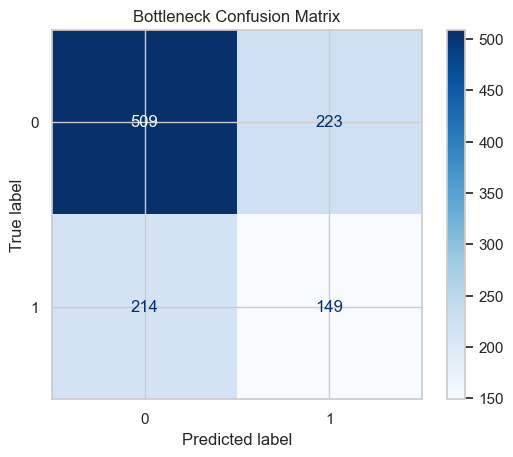

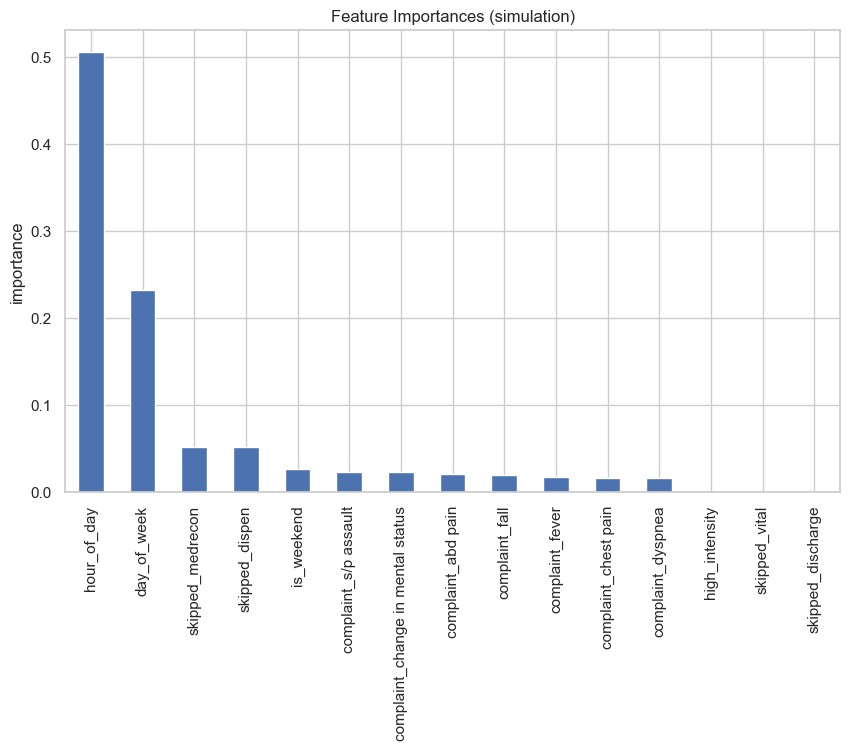

In [28]:
# 7. Evaluation: confusion matrix + feature importance
from sklearn.metrics import ConfusionMatrixDisplay

y_pred = tree.predict(X_test)
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=sorted(y_test.unique())).plot(cmap='Blues')
plt.title('Bottleneck Confusion Matrix')
plt.show()

importances = pd.Series(tree.feature_importances_, index=X_train.columns).sort_values(ascending=False)
plt.figure(figsize=(10,6))
importances.head(30).plot(kind='bar')
plt.title('Feature Importances (simulation)')
plt.ylabel('importance')
plt.show()

In [29]:
# 8. Save model and binarizer for backend
OUT_DIR = DATA_DIR / 'model_artifacts'
OUT_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(tree, OUT_DIR / 'rf_bottleneck_simulation.joblib')
if mlb is not None:
    joblib.dump(mlb, OUT_DIR / 'chiefcomplaint_mlb_simulation.joblib')
print('saved artifacts to', OUT_DIR)

saved artifacts to model_artifacts
